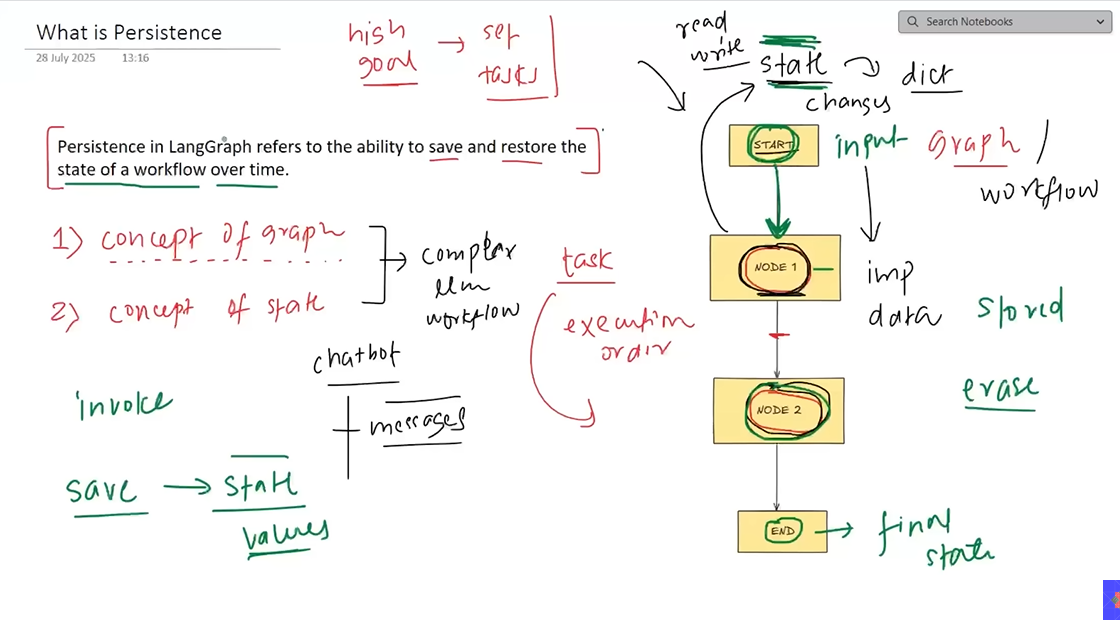

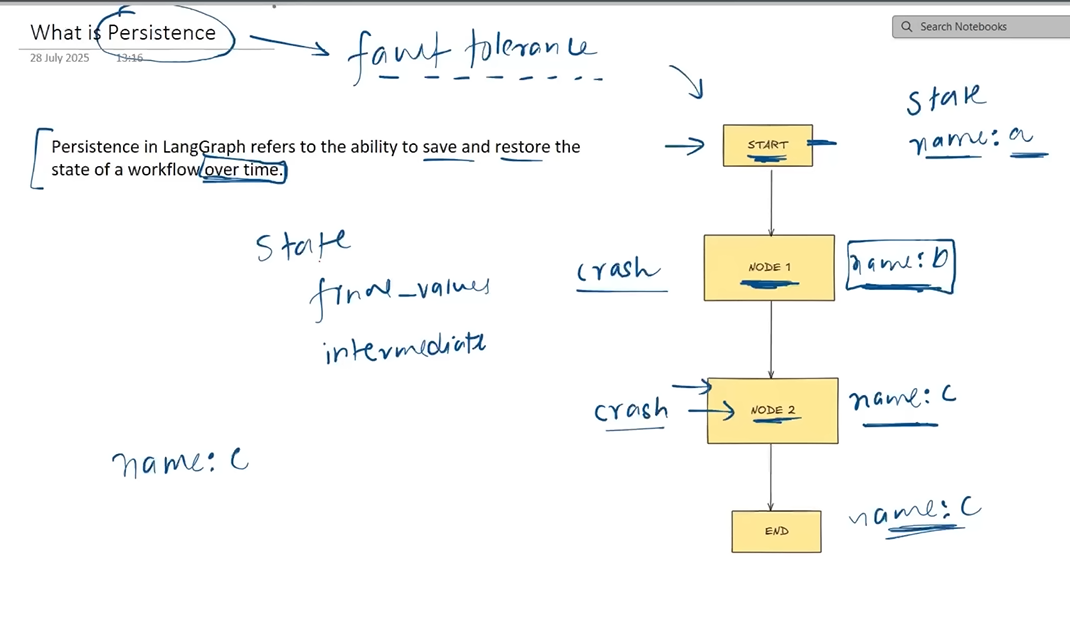

1. ye states ki final and intermediate sbhi values ko store krta h
2. agr kisi node pr worflow crash ho gya to hum whi se worlflow ko strt kr skte h iss feature ko fault tolerence bolte h 
3. example past convp with chatbot ko resume krna tp use liye persiistence chhiye hoga taaki convo ussi node se initialize ho

# checkpoint
 is a complete snapshot of your graph's state saved automatically at every execution step (called a "super-step"). Checkpointers provide short-term, thread-scoped memory

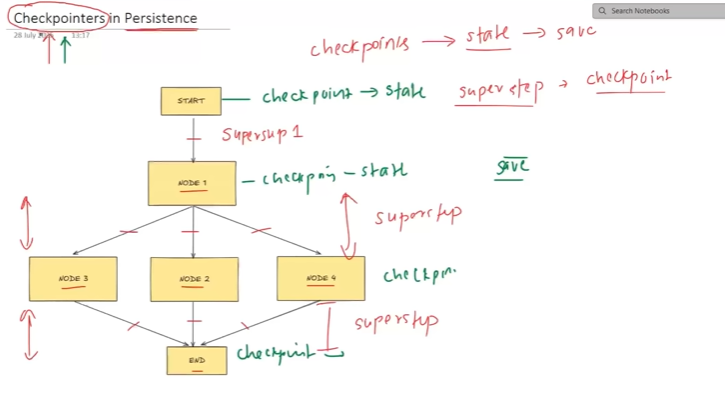

every superstep pr state save kr leta h 
ex:
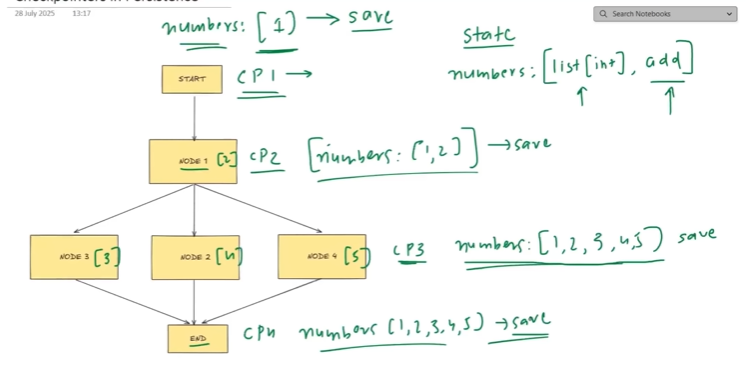

In LangGraph, 
## thread
 represents a single, isolated conversation or run history of your graph.

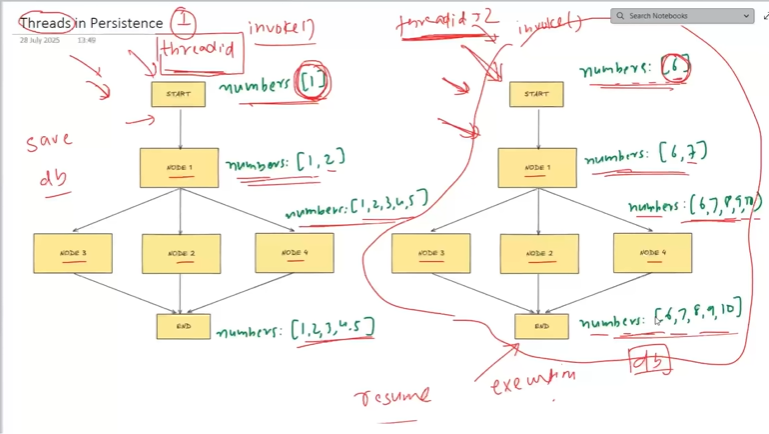

diff graph ko saved with diff thread id so that can bhi resumed or accesses easily

In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [3]:
load_dotenv()
llm = ChatGroq(model = "openai/gpt-oss-120b")

In [4]:
class shayariState(TypedDict):
    topic : str
    shayari :str
    explanation : str

In [12]:
def generate_shayari(state : shayariState):
    prompt = f'write a short shayari in hindi on topic {state["topic"]}'
    res = llm.invoke(prompt).content
    return {'shayari': res}

In [13]:
def generate_explanation(state : shayariState):
    prompt = f'write short explanation of shayari in english on - {state["shayari"]}'
    res = llm.invoke(prompt).content
    return {'explanation': res}

In [14]:
graph = StateGraph(shayariState)

graph.add_node('generate_shayari',generate_shayari)
graph.add_node('generate_explanation',generate_explanation)

graph.add_edge(START,'generate_shayari')
graph.add_edge('generate_shayari','generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)



In [15]:
config1 = {"configurable" : {"thread_id" : "1"}}
workflow.invoke({'topic':'girl'},config=config1)

{'topic': 'girl',
 'shayari': 'बहकती है जब वो मुस्कान‑की रौशनी,  \nहर दिल में बुनती है नई कहानी।  \nचाँदनी से भी कोमल, फूलों से भी नाज़ुक,  \nवो लड़की है, जो हर सांस में बसी ज़िंदगानी।',
 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe verses celebrate the enchanting power of a girl’s smile.  \n\n- **“When the light of her smile leads one astray”** – The poet likens her smile to a radiant beam that draws people in, making them lose themselves in its charm.  \n- **“It weaves a new story in every heart”** – That irresistible glow inspires fresh emotions and fantasies in everyone who experiences it, as if each heart begins a new tale.  \n- **“Softer than moonlight, more delicate than flowers”** – The poet uses gentle, celestial imagery to stress her subtlety and grace; she is more tender than the silvery glow of the moon and more fragile than the most exquisite blossom.  \n- **“She is the girl who lives in every breath of life”** – She becomes an essential part of exi

In [16]:

workflow.get_state(config1)

StateSnapshot(values={'topic': 'girl', 'shayari': 'बहकती है जब वो मुस्कान‑की रौशनी,  \nहर दिल में बुनती है नई कहानी।  \nचाँदनी से भी कोमल, फूलों से भी नाज़ुक,  \nवो लड़की है, जो हर सांस में बसी ज़िंदगानी।', 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe verses celebrate the enchanting power of a girl’s smile.  \n\n- **“When the light of her smile leads one astray”** – The poet likens her smile to a radiant beam that draws people in, making them lose themselves in its charm.  \n- **“It weaves a new story in every heart”** – That irresistible glow inspires fresh emotions and fantasies in everyone who experiences it, as if each heart begins a new tale.  \n- **“Softer than moonlight, more delicate than flowers”** – The poet uses gentle, celestial imagery to stress her subtlety and grace; she is more tender than the silvery glow of the moon and more fragile than the most exquisite blossom.  \n- **“She is the girl who lives in every breath of life”** – She becomes an es

In [17]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'girl', 'shayari': 'बहकती है जब वो मुस्कान‑की रौशनी,  \nहर दिल में बुनती है नई कहानी।  \nचाँदनी से भी कोमल, फूलों से भी नाज़ुक,  \nवो लड़की है, जो हर सांस में बसी ज़िंदगानी।', 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe verses celebrate the enchanting power of a girl’s smile.  \n\n- **“When the light of her smile leads one astray”** – The poet likens her smile to a radiant beam that draws people in, making them lose themselves in its charm.  \n- **“It weaves a new story in every heart”** – That irresistible glow inspires fresh emotions and fantasies in everyone who experiences it, as if each heart begins a new tale.  \n- **“Softer than moonlight, more delicate than flowers”** – The poet uses gentle, celestial imagery to stress her subtlety and grace; she is more tender than the silvery glow of the moon and more fragile than the most exquisite blossom.  \n- **“She is the girl who lives in every breath of life”** – She becomes an e

In [18]:

config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'shayari': 'पास्ता की थाली में, इश्क़ का ज़ायका,  \nहर नूडल में बसी, यादों की परतें सजी।  \n\nसॉस की खुशबू में खो जाएँ हम सब,  \nदिल की धड़कन भी बन जाएँ लज़ीज़ रब।',
 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe couplet uses a culinary metaphor to describe the experience of love.  \n\n1. **“पास्ता की थाली में, इश्क़ का ज़ायका”** –  \n   The poet imagines a plate of pasta as if it were seasoned with the flavor of love. Just as a dish is enhanced by its spices, the speaker’s life is enriched by the taste of romance.\n\n2. **“हर नूडल में बसी, यादों की परतें सजी.”** –  \n   Each noodle represents a thread of memory. The layers of past moments are woven into every strand, suggesting that every bite (or every moment) carries a recollection of shared experiences.\n\n3. **“सॉस की खुशबू में खो जाएँ हम सब,”** –  \n   The aroma of the sauce draws everyone in, symbolising how love’s scent—its allure, warmth, and sensuality—engulfs the lovers, making them

In [31]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'shayari': 'पास्ता की थाली में, इश्क़ का ज़ायका,  \nहर नूडल में बसी, यादों की परतें सजी।  \n\nसॉस की खुशबू में खो जाएँ हम सब,  \nदिल की धड़कन भी बन जाएँ लज़ीज़ रब।', 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe couplet uses a culinary metaphor to describe the experience of love.  \n\n1. **“पास्ता की थाली में, इश्क़ का ज़ायका”** –  \n   The poet imagines a plate of pasta as if it were seasoned with the flavor of love. Just as a dish is enhanced by its spices, the speaker’s life is enriched by the taste of romance.\n\n2. **“हर नूडल में बसी, यादों की परतें सजी.”** –  \n   Each noodle represents a thread of memory. The layers of past moments are woven into every strand, suggesting that every bite (or every moment) carries a recollection of shared experiences.\n\n3. **“सॉस की खुशबू में खो जाएँ हम सब,”** –  \n   The aroma of the sauce draws everyone in, symbolising how love’s scent—its allure, warmth, and sensuality—engulfs the

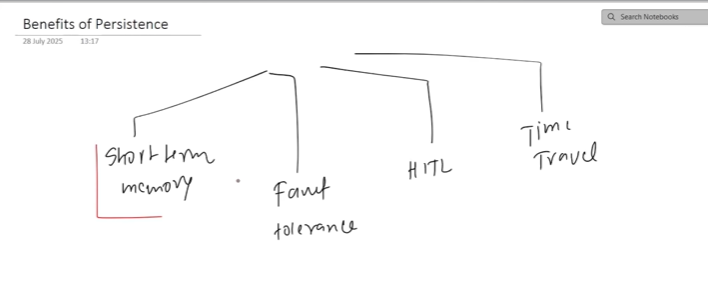

## time travel

you can go back to previous states and initialize the graph again from that state

In [34]:
workflow.get_state({"configurable":{"thread_id":"2","checkpoint_id":"1f1e2583-ae89-614c-8001-904920d95f83"}})

StateSnapshot(values={'topic': 'pasta', 'shayari': 'पास्ता की थाली में, इश्क़ का ज़ायका,  \nहर नूडल में बसी, यादों की परतें सजी।  \n\nसॉस की खुशबू में खो जाएँ हम सब,  \nदिल की धड़कन भी बन जाएँ लज़ीज़ रब।'}, next=('generate_explanation',), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1e2583-ae89-614c-8001-904920d95f83'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-17T07:26:39.851521+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e2583-a5dc-6f37-8000-bd36fca9ab77'}}, tasks=(PregelTask(id='a6fb2ddf-e271-ad21-a202-0e230756044b', name='generate_explanation', path=('__pregel_pull', 'generate_explanation'), error=None, interrupts=(), state=None, result={'explanation': '**Explanation of the Shayari (in English)**  \n\nThe couplet uses a culinary metaphor to describe the experience of love.  \n\n1. **“पास्ता की थाली में, इश्क़ का ज़ायका”** –  \n   The poet imagines a plate of pasta as if it we

abb hum invoke kr skte h graph ko and vo issi state se strt hoga

In [35]:
workflow.invoke(None, {"configurable": {"thread_id": "2", "checkpoint_id": "1f1e2583-ae89-614c-8001-904920d95f83"}})

{'topic': 'pasta',
 'shayari': 'पास्ता की थाली में, इश्क़ का ज़ायका,  \nहर नूडल में बसी, यादों की परतें सजी।  \n\nसॉस की खुशबू में खो जाएँ हम सब,  \nदिल की धड़कन भी बन जाएँ लज़ीज़ रब।',
 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe couplet uses the everyday image of a pasta dish to paint a vivid metaphor for love and memory.  \n\n- **“पास्ता की थाली में, इश्क़ का ज़ायका”** – The flavor of love is likened to the taste that fills a plate of pasta. Just as a well‑seasoned pasta delights the palate, love adds a rich, lingering savor to life.  \n\n- **“हर नूडल में बसी, यादों की परतें सजी”** – Each noodle is described as being wrapped in layers of memories. The thin strands of pasta become carriers of past moments, suggesting that every little detail of a relationship is infused with recollection.  \n\n- **“सॉस की खुशबू में खो जाएँ हम सब”** – The aroma of the sauce represents the intoxicating atmosphere of romance. The scent draws everyone in, symbolising how love’s e

In [36]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'shayari': 'पास्ता की थाली में, इश्क़ का ज़ायका,  \nहर नूडल में बसी, यादों की परतें सजी।  \n\nसॉस की खुशबू में खो जाएँ हम सब,  \nदिल की धड़कन भी बन जाएँ लज़ीज़ रब।', 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe couplet uses the everyday image of a pasta dish to paint a vivid metaphor for love and memory.  \n\n- **“पास्ता की थाली में, इश्क़ का ज़ायका”** – The flavor of love is likened to the taste that fills a plate of pasta. Just as a well‑seasoned pasta delights the palate, love adds a rich, lingering savor to life.  \n\n- **“हर नूडल में बसी, यादों की परतें सजी”** – Each noodle is described as being wrapped in layers of memories. The thin strands of pasta become carriers of past moments, suggesting that every little detail of a relationship is infused with recollection.  \n\n- **“सॉस की खुशबू में खो जाएँ हम सब”** – The aroma of the sauce represents the intoxicating atmosphere of romance. The scent draws everyone in, symb

to abb yha pr humne time travel kra wapas gye and usse re execute kiya
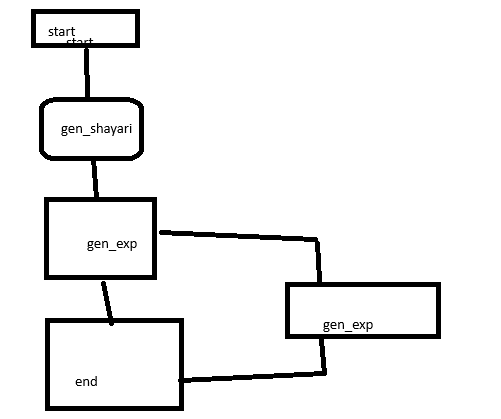

## Updating State

In [38]:
workflow.update_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f1e257b-e94c-6c0f-8000-94ae42c8e945", "checkpoint_ns": ""}}, {'topic':'samosa'})


{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e2629-0dbf-6c65-8001-7221b60b9c3d'}}

In [40]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f1e2629-0dbf-6c65-8001-7221b60b9c3d"}})


{'topic': 'samosa',
 'shayari': 'सुनो दिल‑से एक कहानी,  \nहर कोने में बसी है सुगंध़ की निशानी—  \nसामोसे की कुरकुरी बाहों में,  \nमसालों की मोहब्बत, जीभ पे नाचती फ़सानी।  \n\nएक बाइट, फिर दो, फिर तीन,  \nखुशियों का खजाना, बन जाता है मीठा‑मीठा सीन।  \nभूख की रौशनी में जब जलता है दीप,  \nसामोसा बनता है दिल का सबसे मीठा रीफ़।',
 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe verses are a playful, sensory‑rich shayari that treats a humble snack—*samosa*—as a metaphor for love, joy and the fragrant memories that linger in every corner of the heart.  \n\n1. **“Suno dil‑se ek kahani… har kone mein basi hai sugandh ki nishani”** – The poet invites the listener to hear a story from the depths of the heart, pointing out that the scent of something sweet and spicy has settled everywhere, like an invisible sign of affection.  \n\n2. **“Samosa ki kurkuri baahon mein, masalon ki mohabbat, jeebh pe naachti fasani”** – The crisp, golden “arms” of the samosa hold a love of spices 

In [41]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'shayari': 'सुनो दिल‑से एक कहानी,  \nहर कोने में बसी है सुगंध़ की निशानी—  \nसामोसे की कुरकुरी बाहों में,  \nमसालों की मोहब्बत, जीभ पे नाचती फ़सानी।  \n\nएक बाइट, फिर दो, फिर तीन,  \nखुशियों का खजाना, बन जाता है मीठा‑मीठा सीन।  \nभूख की रौशनी में जब जलता है दीप,  \nसामोसा बनता है दिल का सबसे मीठा रीफ़।', 'explanation': '**Explanation of the Shayari (in English)**  \n\nThe verses are a playful, sensory‑rich shayari that treats a humble snack—*samosa*—as a metaphor for love, joy and the fragrant memories that linger in every corner of the heart.  \n\n1. **“Suno dil‑se ek kahani… har kone mein basi hai sugandh ki nishani”** – The poet invites the listener to hear a story from the depths of the heart, pointing out that the scent of something sweet and spicy has settled everywhere, like an invisible sign of affection.  \n\n2. **“Samosa ki kurkuri baahon mein, masalon ki mohabbat, jeebh pe naachti fasani”** – The crisp, golden “arms” of the samosa ho

# Fault Tolerance

In [42]:

from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import InMemorySaver
from typing import TypedDict
import time

In [50]:
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str

In [48]:
# 2. Define steps
def step_1(state: CrashState) -> CrashState:
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}

def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)")
    time.sleep(10)  # Simulate long-running hang
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}


In [45]:
# 3. Build the graph
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

In [49]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")

▶️ Running graph: Please manually interrupt during Step 2...
✅ Step 1 executed
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)
✅ Step 3 executed


In [47]:
# 6. Re-run to show fault-tolerant resume
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)


🔁 Re-running the graph to demonstrate fault tolerance...
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)
✅ Step 3 executed

✅ Final State: {'input': 'start', 'step1': 'done', 'step2': 'done'}


In [ ]:

list(graph.get_state_history({"configurable": {"thread_id": 'thread-1'}}))